# 09 Coverage proxies across the audit groups, and the column catalogue
The equity question asked with observable stand-ins: do road density, places per building, buildings per home and the Microsoft share differ between rural and urban, low- and high-vulnerability, tribal and other, and low- and high-hazard tracts, and how much of any difference survives once region and urbanity are accounted for?

Hazard and vulnerability groups use the within-region top quartile (notebook 08 showed that a pooled threshold makes "high heat" almost entirely Texas).

**This is a descriptive audit.** The hidden target cannot be computed, so each proxy is an observable feature of Overture itself, not a coverage gap. A difference here is an association worth testing later, not a finding about coverage and not a causal claim. The last section also lists every column with its role (structural, Overture, audit-only, excluded), which is the hand-off to modelling.

In [1]:
from common import *
import statsmodels.formula.api as smf
b = pd.read_parquet(OUT / "base_table.parquet")
au = pd.read_parquet(OUT / "audit_strata.parquet")
d = b.merge(au.drop(columns=["region", "state_usps", "pop_total", "pct_urban", "ur_class"]), on="GEOID")
d = d[d.region.isin(SCORED)].copy()
d["msft_share"] = d.bldg_n_msft / d.bldg_n.where(d.bldg_n > 0)
d["small_share"] = d.bldg_n_lt30m2 / d.bldg_n.where(d.bldg_n > 0)
d["has_fire"] = (d.poi_n_fire > 0).astype(float); d["has_ems"] = (d.poi_n_ems > 0).astype(float)
d["has_hwy"] = (d.road_km_hwy > 0).astype(float)
d["ur"] = d.ur_class.fillna("Urban")
G = ["rural", "tribal", "high_svi", "high_heat", "high_drought", "high_fire"]
for g in G[2:]: d[g] = d[g + "_wr"]  # top quartile *within region*, so region does not define the group
for g in G: d[g] = d[g].fillna(False).astype(bool)
PROXY = {"log_bldg_per_hu": ("buildings per housing unit", lambda x: np.log(x.bldg_per_hu.where(x.bldg_per_hu > 0))),
         "log_poi_per_bldg": ("places per building", lambda x: np.log(x.poi_per_bldg.where(x.poi_per_bldg > 0))),
         "log_hwy_density": ("highway km per km2", lambda x: np.log1p(100 * x.road_hwy_km_per_km2)),
         "msft_share": ("Microsoft share of buildings", lambda x: x.msft_share),
         "small_share": ("share of footprints under 30 m2", lambda x: x.small_share),
         "has_fire": ("has a fire station place", lambda x: x.has_fire), "has_ems": ("has an EMS place", lambda x: x.has_ems), "has_hwy": ("has a highway-class road", lambda x: x.has_hwy)}
for k, (_, f) in PROXY.items(): d[k] = f(d)
d["lpop"] = np.log1p(d.pop_per_km2.fillna(0)); d["lland"] = np.log(d.land_km2.where(d.land_km2 > 0))
print(d.shape, "| proxies available:", {k: int(d[k].notna().sum()) for k in PROXY})
print("group sizes:", {g: int(d[g].sum()) for g in G})

(9379, 135) | proxies available: {'log_bldg_per_hu': 9299, 'log_poi_per_bldg': 9377, 'log_hwy_density': 9379, 'msft_share': 9377, 'small_share': 9377, 'has_fire': 9379, 'has_ems': 9379, 'has_hwy': 9379}
group sizes: {'rural': 1712, 'tribal': 858, 'high_svi': 2325, 'high_heat': 2496, 'high_drought': 2355, 'high_fire': 2346}


**Takeaway:** The audit uses the 9,379 scored tracts and eight proxies, each computed from Overture alone. Group sizes (within-region top quartile for the hazard and vulnerability groups): rural 1,712, tribal 858, high SVI 2,325, high heat 2,496, high drought 2,355, high wildfire 2,346. Proxies are available for 9,299 to 9,379 tracts (buildings per housing unit needs a nonzero housing count).

## 1. Raw differences, in-group against the rest
Median (or mean for 0/1 proxies) in the group and outside it, pooled over the four regions. This is the naive view and is confounded by region and density.

In [2]:
rows = []
for g in G:
    for k, (lab, _) in PROXY.items():
        x = d.loc[d[g], k].dropna(); y = d.loc[~d[g], k].dropna()
        rows.append(dict(group=g, proxy=k, in_group=x.mean() if k.startswith(("has", "msft", "small")) else x.median(), rest=y.mean() if k.startswith(("has", "msft", "small")) else y.median()))
raw = pd.DataFrame(rows); raw["diff"] = raw.in_group - raw.rest
print(raw.pivot(index="proxy", columns="group", values="diff")[G].round(3).to_string())
print("\n(log proxies: difference of medians on the log scale; 0/1 and share proxies: difference of means)")

group             rural  tribal  high_svi  high_heat  high_drought  high_fire
proxy                                                                        
has_ems           0.037   0.038     0.039      0.008         0.005      0.029
has_fire          0.314   0.145    -0.017     -0.057         0.024      0.205
has_hwy          -0.001  -0.011     0.008      0.003        -0.002     -0.001
log_bldg_per_hu   0.719   0.350    -0.049     -0.093         0.049      0.455
log_hwy_density  -2.280  -1.600     0.359      0.408        -0.243     -1.793
log_poi_per_bldg -0.926  -0.395     0.416      0.205        -0.082     -0.735
msft_share        0.424   0.445     0.043      0.066         0.060      0.204
small_share       0.003  -0.008     0.014     -0.028         0.005      0.000

(log proxies: difference of medians on the log scale; 0/1 and share proxies: difference of means)


**Takeaway:** In raw terms rural tracts look very different: highway density is lower (-2.28 on the log scale), places per building are lower (-0.93), buildings per housing unit are higher (+0.72) and Microsoft supplies 42 points more of the buildings. Tribal and high-wildfire tracts show the same pattern at a smaller scale; high-SVI and high-heat tracts show more places per building (+0.42 and +0.21) and denser highways. Most of this is size and density, as the next section shows.

## 2. Differences after accounting for region, urbanity and density
Regression of each proxy on one group at a time, adding region, Census urban class (except for the rural group itself, which it defines), log population density and log land area. Heteroskedasticity-robust 95% intervals. Read as "within the same region and a similar kind of place".

group             rural  tribal  high_svi  high_heat  high_drought  high_fire
proxy                                                                        
has_ems          -0.046   0.045     0.046      0.017         0.000     -0.006
has_fire          0.012   0.016     0.023     -0.013        -0.003      0.004
has_hwy          -0.003  -0.007     0.008      0.004        -0.002     -0.004
log_bldg_per_hu  -0.140  -0.223    -0.001     -0.098         0.075     -0.037
log_hwy_density  -0.319  -0.021     0.132      0.085        -0.066     -0.224
log_poi_per_bldg -0.332   0.110     0.212      0.105        -0.055     -0.187
msft_share        0.108   0.292     0.090      0.124         0.032     -0.031
small_share      -0.009  -0.078     0.014     -0.028         0.005     -0.002

intervals excluding 0:
group            rural tribal high_svi high_heat high_drought high_fire
proxy                                                                  
has_ems              *      *        *         *    

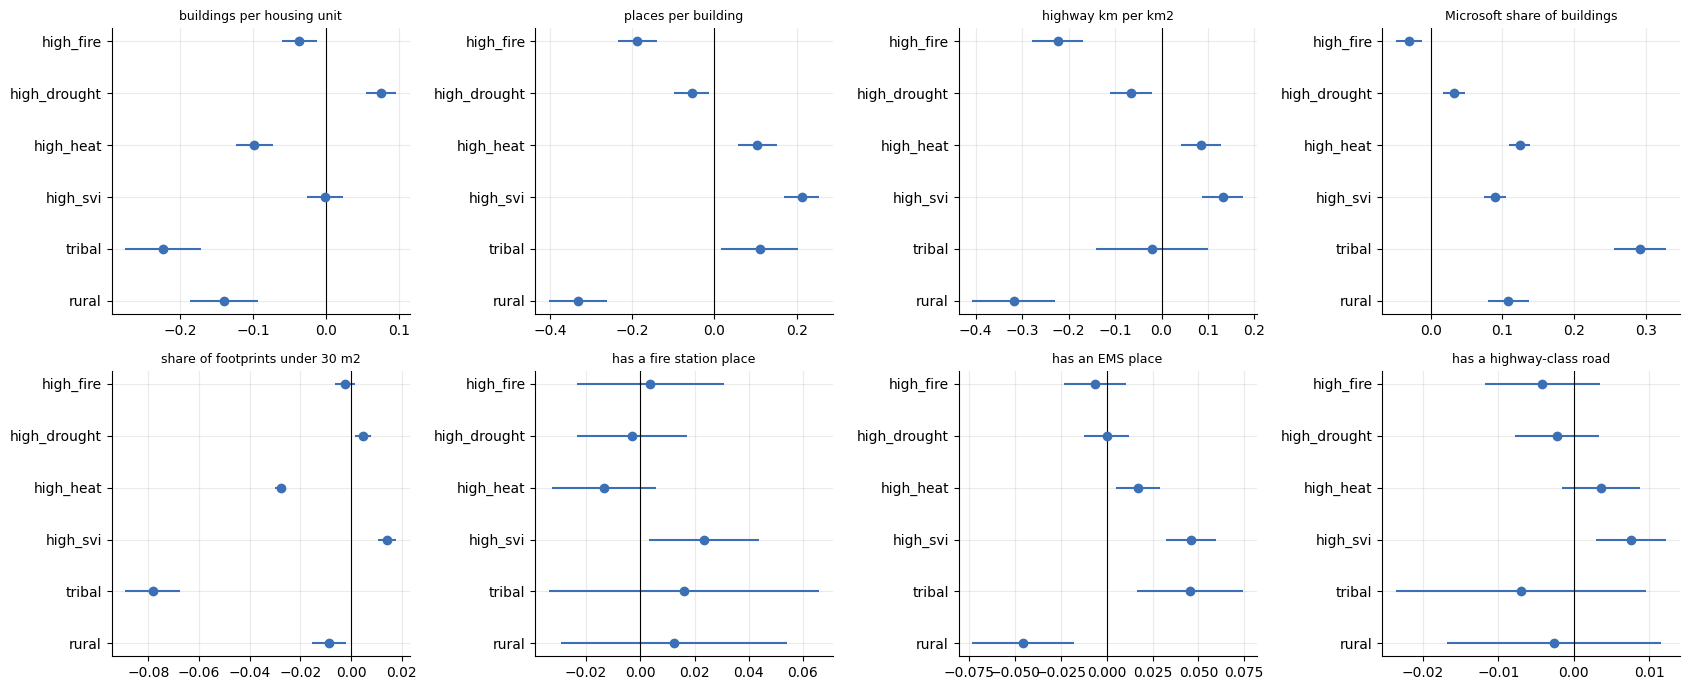

In [3]:
res = []
for g in G:
    for k in PROXY:
        z = d[[k, g, "region", "ur", "lpop", "lland"]].dropna(); z[g] = z[g].astype(int)
        if z[g].sum() < 30: continue
        ctrl = "C(region) + lpop + lland" + ("" if g == "rural" else " + C(ur)")  # the Census urban class IS the rural group, so it is not a control for it
        m = smf.ols(f"{k} ~ {g} + {ctrl}", z).fit(cov_type="HC3")
        lo, hi_ = m.conf_int().loc[g]; res.append(dict(group=g, proxy=k, coef=m.params[g], lo=lo, hi=hi_, n=len(z), n_group=int(z[g].sum())))
R = pd.DataFrame(res)
tab = R.assign(sig=np.where((R.lo > 0) | (R.hi < 0), "*", ""))
print(tab.pivot(index="proxy", columns="group", values="coef")[G].round(3).to_string())
print("\nintervals excluding 0:"); print(tab.pivot(index="proxy", columns="group", values="sig")[G].to_string())
fig, ax = plt.subplots(2, 4, figsize=(17, 7))
for a_, (k, (lab, _)) in zip(ax.ravel(), PROXY.items()):
    q = R[R.proxy == k].set_index("group").reindex(G); a_.errorbar(q.coef, range(len(q)), xerr=[q.coef - q.lo, q.hi - q.coef], fmt="o", color="#3b6fb6"); a_.axvline(0, color="k", lw=.8); a_.set_yticks(range(len(G))); a_.set_yticklabels(G); a_.set_title(lab, fontsize=9)
plt.show()

**Takeaway:** Within the same region, urban class, density and land area, the differences shrink and sometimes change sign. Buildings per housing unit in rural tracts goes from +0.72 raw to -0.14 adjusted, in tribal tracts from +0.35 to -0.22 and in high-wildfire tracts from +0.46 to -0.04. The differences that remain (intervals excluding zero) are: rural tracts have fewer places per building (-0.33 on the log scale, about 28% fewer) and lower highway density (-0.32), and a 4.6-point lower chance of an EMS place; high-wildfire tracts have fewer places per building (-0.19) and lower highway density (-0.22); high-SVI tracts have more places per building (+0.21, about 24% more), more highway density (+0.13) and a 2.3-point higher chance of a fire place; high-heat tracts have more places per building (+0.11); high-drought tracts have slightly more buildings per housing unit (+0.08). None of the six groups is systematically worse mapped on every proxy, so no single "less covered" story fits the groups.
The most consistent pattern is provenance: the Microsoft share of buildings is higher in rural (+10.8 points), tribal (+29.2), high-SVI (+9.0) and high-heat (+12.4) tracts even after adjustment, and about 3 points lower in high-wildfire tracts. Because the hidden building gap is measured against Microsoft footprints, this association between supplier and group is a candidate for the bias write-up, as a pattern to test and not as a finding.

## 3. Is the pooled picture the same in each region?
The same group contrast within each region, for the proxies where the adjusted difference was clearest. A pooled difference driven by one region would show up here as a sign that flips.

In [4]:
focus = ["log_poi_per_bldg", "log_hwy_density", "log_bldg_per_hu", "has_fire"]
rows = []
for g in ["rural", "tribal", "high_svi"]:
    for r in SCORED:
        z = d[d.region == r]
        for k in focus:
            x = z.loc[z[g], k].mean(); y = z.loc[~z[g], k].mean()
            rows.append(dict(group=g, region=r, proxy=k, diff=x - y, n_group=int(z[g].sum())))
rr = pd.DataFrame(rows)
for g in ["rural", "tribal", "high_svi"]:
    print(f"== {g}: in-group minus rest (mean)"); print(rr[rr.group == g].pivot(index="proxy", columns="region", values="diff")[SCORED].round(3).to_string()); print("group sizes:", rr[(rr.group == g) & (rr.proxy == focus[0])].set_index("region").n_group.to_dict(), "\n")

== rural: in-group minus rest (mean)
region            maricopa-az  northern-ca  eastern-ok  south-central-tx
proxy                                                                   
has_fire                0.279        0.319       0.386             0.285
log_bldg_per_hu         0.801        0.712       0.691             0.944
log_hwy_density        -2.686       -2.252      -1.741            -2.008
log_poi_per_bldg       -0.795       -0.777      -1.018            -0.995
group sizes: {'maricopa-az': 163, 'northern-ca': 147, 'eastern-ok': 411, 'south-central-tx': 991} 

== tribal: in-group minus rest (mean)
region            maricopa-az  northern-ca  eastern-ok  south-central-tx
proxy                                                                   
has_fire                0.203        0.179       0.185            -0.288
log_bldg_per_hu         0.540        0.412       0.199             0.358
log_hwy_density        -2.073       -0.977      -0.938            -1.255
log_poi_per_bldg      

**Takeaway:** Within each region the rural pattern keeps its direction: highway density is lower by 1.7 to 2.7 log points, places per building lower by 0.78 to 1.02, buildings per housing unit higher by 0.69 to 0.94 and fire presence higher by 28 to 39 points (the last is mostly a tract-size effect). High-SVI tracts have more places per building in every region (+0.26 to +0.48). Tribal tracts differ in direction between regions only where the group is tiny (one Texas tract), so tribal results effectively come from Eastern OK and Maricopa. The regressions above control for region, so pooled differences are not driven by one region.

## 4. Strata columns that duplicate Overture or the removed reference layers
Some strata columns count buildings, housing or people. If one tracks Overture's own count it carries no independent information, and if it is derived from a removed reference layer, using it would approximate the hidden target. Both are compared with Overture here and excluded from modelling.

In [5]:
S = pd.read_parquet(tracts_parquet("strata-tract-table")); S["GEOID"] = S.GEOID.astype(str)
cnt = [c for c in S.columns if "Count" in c or c in ("carbonplan_buildings",)]
x = b.merge(S[["GEOID"] + cnt], on="GEOID"); x = x[x.region.isin(SCORED)]
rows = []
for c_ in cnt:
    m = x[c_].notna() & (x[c_] > 0) & (x.bldg_n > 0)
    rows.append(dict(column=c_, tracts=int(m.sum()), spearman_vs_overture_buildings=x.loc[m, c_].corr(x.loc[m, "bldg_n"], method="spearman"), median_ratio_to_overture=(x.loc[m, c_] / x.loc[m, "bldg_n"]).median(),
                     spearman_vs_housing_units=x.loc[m, c_].corr(x.loc[m, "housing_units"], method="spearman")))
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nstrata columns containing 'Count':", cnt)

                column  tracts  spearman_vs_overture_buildings  median_ratio_to_overture  spearman_vs_housing_units
usfs_BuildingCount_sum    9377                           0.955                     0.982                      0.495
      usfs_HUCount_sum    9362                           0.484                     0.924                      0.957
     usfs_PopCount_sum    9364                           0.479                     2.638                      0.797
  carbonplan_buildings    9377                           0.999                     1.002                      0.482

strata columns containing 'Count': ['usfs_BuildingCount_sum', 'usfs_HUCount_sum', 'usfs_PopCount_sum', 'carbonplan_buildings']


**Takeaway:** Four strata columns count buildings, housing or people. `carbonplan_buildings` is a copy of Overture's own building count (Spearman 0.999, median ratio 1.002). `usfs_BuildingCount_sum` tracks it almost as closely (0.955, ratio 0.98), and `usfs_HUCount_sum` and `usfs_PopCount_sum` follow ACS housing units (0.96 and 0.80). None gives information independent of Overture or ACS, and their derivation from reference layers is not documented here, so all four are excluded from modelling.

## 5. Column catalogue and roles
Every column the EDA produced, with its role. `structural` columns may describe how many features a tract should have; `overture` columns are what Overture contains (targets of expectation models or provenance signals); `audit` columns define groups and must never feed an expectation; `excluded` columns duplicate Overture or a removed reference layer.

In [6]:
def role(c_):
    if c_ in ("GEOID", "region", "state_usps", "STATEFP", "COUNTYFP"): return "identity"
    if c_ in ("land_km2", "water_km2", "water_share", "housing_units", "pop_total", "pop_per_km2", "pop_per_hu", "hu_per_km2", "tract_area_km2", "ALAND", "AWATER", "geo_vs_aland"): return "structural"
    if c_ in ("pct_urban", "ur_class"): return "audit"
    if c_.startswith(("bldg_src_n", "bldg_n_osm", "bldg_n_msft", "bldg_n_google", "bldg_n_esri", "bldg_n_other", "bldg_year", "bldg_n_upd", "bldg_n_height", "bldg_n_floors", "bldg_n_class", "bldg_n_subtype", "bldg_n_name", "poi_src_n", "poi_conf", "poi_n_conf", "poi_n_closed", "poi_n_open", "poi_n_nocat", "poi_n_distinct", "ru_", "bldg_n_lt30", "bldg_n_ge300")): return "overture_quality_provenance"
    if c_.startswith(("bldg", "road", "rail", "infra", "poi")): return "overture"
    return "other"
cat = pd.DataFrame({"column": b.columns, "table": "base_table"}); cat["role"] = cat.column.map(role)
au_cols = [c_ for c_ in au.columns if c_ not in ("GEOID", "region", "state_usps", "pop_total", "pct_urban", "ur_class")]
cat = pd.concat([cat, pd.DataFrame({"column": au_cols, "table": "audit_strata", "role": "audit"}),
                 pd.DataFrame({"column": [c_ for c_ in cnt if "Count" in c_ or c_ == "carbonplan_buildings"], "table": "strata (not saved)", "role": "excluded"})], ignore_index=True)
cat.to_csv(OUT / "column_catalog.csv", index=False)
print(cat.groupby(["table", "role"]).size().to_string()); print("\nstructural:", cat[cat.role == "structural"].column.tolist()); print("\nexcluded:", cat[cat.role == "excluded"].column.tolist())

table               role                       
audit_strata        audit                          40
base_table          audit                           2
                    identity                        5
                    overture                       36
                    overture_quality_provenance    29
                    structural                     12
strata (not saved)  excluded                        4

structural: ['tract_area_km2', 'housing_units', 'ALAND', 'AWATER', 'pop_total', 'land_km2', 'water_km2', 'water_share', 'hu_per_km2', 'pop_per_km2', 'pop_per_hu', 'geo_vs_aland']

excluded: ['usfs_BuildingCount_sum', 'usfs_HUCount_sum', 'usfs_PopCount_sum', 'carbonplan_buildings']


**Takeaway:** The column catalogue (`eda_outputs/column_catalog.csv`) covers 5 identity, 12 structural, 36 Overture count or length, 29 Overture quality or provenance and 2 audit columns in the base table, 40 audit columns in the audit table and 4 excluded strata columns. Structural columns may describe how many features a tract should have, audit columns may only define groups, and excluded columns are not used.